<a href="https://colab.research.google.com/github/ibrahimhanifceker/YZ50Codes/blob/main/hafta-10/YZ50Hafta10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from transformers import GPT2LMHeadModel

In [3]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")
sd_hf = model_hf.state_dict()

for k, v in sd_hf.items():
    print(k, v.shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [4]:
tot_param = 0;
for k, v in sd_hf.items():
    tot_param += v.nelement()

print(f"{tot_param :.2e}")

1.63e+08


In [5]:
from transformers import pipeline, set_seed
generator = pipeline('text-generation', model='gpt2')
set_seed(42)
generator("Hello, I am a langauge model,", max_length=30, num_return_sequences=5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'Hello, I am a langauge model, so I have to say that some people are going to be interested in the idea of creating a 3'},
 {'generated_text': 'Hello, I am a langauge model, I am a langauge model of myself.\n\nThe next question is, do you have'},
 {'generated_text': 'Hello, I am a langauge model, I am an avian model, and I am a model of a man. I think I am'},
 {'generated_text': "Hello, I am a langauge model, and it's not about me. On the contrary, it's about me. I was born in"},
 {'generated_text': 'Hello, I am a langauge model, not a scientist or even a journalist and I have no idea what this topic is about. This is'}]

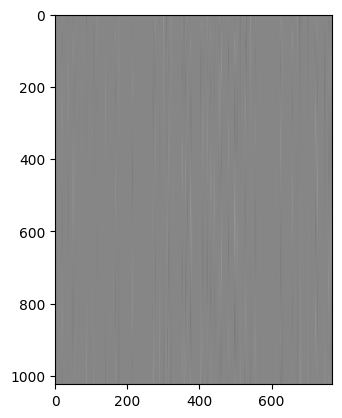

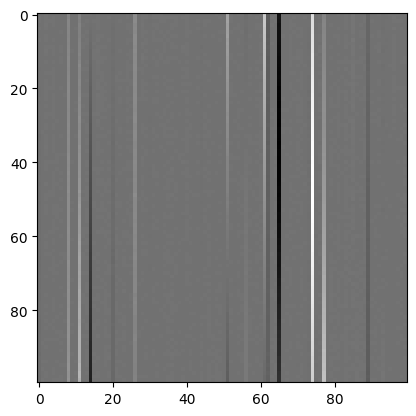

In [6]:
import matplotlib.pyplot as plt

plt.figure(0)
plt.imshow(sd_hf["transformer.wpe.weight"][:, :], cmap="gray")
plt.figure(1);
plt.imshow(sd_hf["transformer.wpe.weight"][500:600, 300:400], cmap="gray")

In [7]:
# Pozisyon embeddinglerinde bazi indekslerin her pozisyon icin aktif ya da deaktif oldugunu gorebiliriz.
# Ayrica, bazi embedding dimnesionlari pozisyonla birlikte artan ya da azalan degerlere sahip.

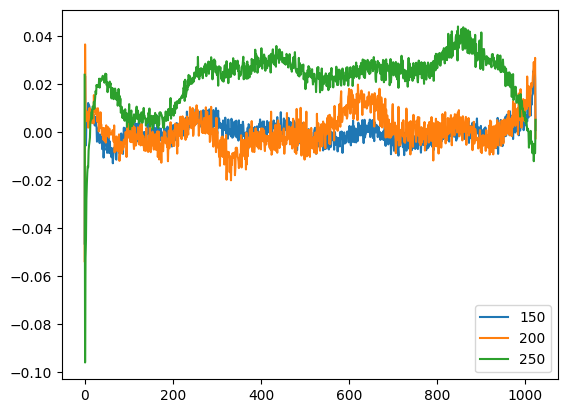

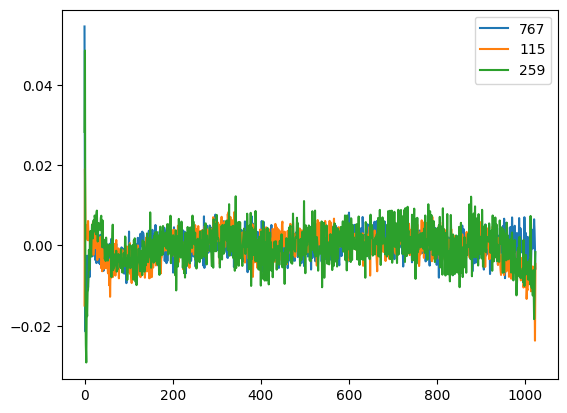

In [8]:
plt.figure()
plt.plot(sd_hf["transformer.wpe.weight"][:, 150], label='150');
plt.plot(sd_hf["transformer.wpe.weight"][:, 200], label='200');
plt.plot(sd_hf["transformer.wpe.weight"][:, 250], label='250');
plt.legend();
plt.figure()
plt.plot(sd_hf["transformer.wpe.weight"][:, -1], label='767');
plt.plot(sd_hf["transformer.wpe.weight"][:, 115], label='115');
plt.plot(sd_hf["transformer.wpe.weight"][:, 259], label='259');
plt.legend();

In [9]:
# Pozisyon embeddinglerinin ayni dimension icin genelde dalga gibi davrandigini goruyorum.

In [10]:
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import math

In [11]:
class CasualSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size).view(1, 1, config.block_size, config.block_size)))

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1) * (1.0 / math.sqrt(k.size(-1))))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y


In [12]:
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

In [13]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CasualSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

In [14]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head : int = 12
    n_embd: int  = 768

In [15]:
class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B*T, -1), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        print(f"loading weights from the model {model_type}")
        config_args = {
            'gpt2':         dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-medium':  dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-large':   dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-xl':      dict(n_layer=12, n_head=12, n_embd=768),
        }[model_type]
        config_args['vocab_size'] = 50257
        config_args['block_size'] = 1024
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = sd.keys()
        sd_keys = [k for k in sd_keys if not k.endswith('.attn.bias')]
        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = sd_hf.keys()
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.masked_bias')]
        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith('.attn.bias')]
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: {len(sd_keys_hf)} != {len(sd_keys)}"
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])
        return model

In [16]:
model = GPT.from_pretrained('gpt2')

loading weights from the model gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [17]:
tokens = torch.tensor([[1, 2, 3], [4, 5, 6]])
logits = model(tokens)[0].data
logits_hf = model_hf(tokens)
print(torch.stack((logits, logits_hf[0].data), dim=-1))
print(f"Does the loaded model give the same logits as the original model? {logits.allclose(logits_hf[0].data)}")

tensor([[[[-32.9010, -32.9011],
          [-31.2024, -31.2024],
          [-34.6622, -34.6622],
          ...,
          [-39.4867, -39.4867],
          [-39.8731, -39.8732],
          [-32.2387, -32.2387]],

         [[-55.5208, -55.5207],
          [-53.4285, -53.4285],
          [-56.4767, -56.4767],
          ...,
          [-68.1539, -68.1539],
          [-66.7709, -66.7708],
          [-58.6006, -58.6006]],

         [[-61.7969, -61.7969],
          [-60.5386, -60.5386],
          [-59.5503, -59.5503],
          ...,
          [-75.3206, -75.3206],
          [-72.7731, -72.7731],
          [-65.5706, -65.5706]]],


        [[[-34.2117, -34.2118],
          [-33.7478, -33.7479],
          [-36.0369, -36.0370],
          ...,
          [-41.5752, -41.5752],
          [-41.8641, -41.8642],
          [-33.8159, -33.8160]],

         [[-76.9006, -76.9006],
          [-78.5744, -78.5744],
          [-75.4780, -75.4781],
          ...,
          [-89.0610, -89.0610],
          [-87.8098

In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("The current device used is " + device)

num_return_sequences = 5
max_length = 30

model = GPT.from_pretrained('gpt2')
model.eval()
model.to(device)

The current device used is cuda
loading weights from the model gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (h): ModuleList(
      (0-11): 12 x Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): CasualSelfAttention(
          (c_attn): Linear(in_features=768, out_features=2304, bias=True)
          (c_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (c_fc): Linear(in_features=768, out_features=3072, bias=True)
          (gelu): GELU(approximate='tanh')
          (c_proj): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [19]:
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode("Would you like to learn something new? ")
print(len(tokens))
tokens = torch.tensor(tokens, dtype=torch.long)
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
x = tokens.to(device)

9


In [20]:
def generate_text():
    global x
    torch.manual_seed(42)
    torch.cuda.manual_seed(42)
    while x.size(1) < max_length:
        with torch.no_grad():
            logits = model(x)[0]
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
            idx = torch.multinomial(topk_probs, 1)
            xcol = torch.gather(topk_indices, -1, idx)
            x = torch.cat((x, xcol), dim=1)

In [21]:
generate_text()

for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(decoded)

Would you like to learn something new?  If so, you can send me a review and I will let you know. If you don't
Would you like to learn something new?  The New York Times  doesn't seem thrilled to have the '90s as its annual feature
Would you like to learn something new? ________________________________________ For those of you who like to write some code you could also check out the documentation on GitHub
Would you like to learn something new?  The Best of the Best is at http://www.chicago-bios.com/ 
Would you like to learn something new?  Tell me about it at my Ask Me Anything
I don't expect to have to do the whole


In [22]:
max_length = 30

tokens = enc.encode("Yeni bir şey öğrenmek ister misin? ")
print(len(tokens))
tokens = torch.tensor(tokens, dtype=torch.long)
tokens = tokens.unsqueeze(0).repeat(num_return_sequences, 1)
x = tokens.to(device)

generate_text()

for i in range(num_return_sequences):
    tokens = x[i, :max_length].tolist()
    decoded = enc.decode(tokens)
    print(decoded)

18
Yeni bir şey öğrenmek ister misin? ğrí nüüy nemşenu
Yeni bir şey öğrenmek ister misin? тсе се рас /u
Yeni bir şey öğrenmek ister misin? ik: ĆisĿĿ ĵk
Yeni bir şey öğrenmek ister misin? ich inıyın, dıyaşı
Yeni bir şey öğrenmek ister misin? iz han zu gekud yemmü


In [23]:
import os

if not os.path.isfile("input.txt"):
    !wget https://raw.githubusercontent.com/karpathy/char-rnn/refs/heads/master/data/tinyshakespeare/input.txt

with open('input.txt', 'r') as f:
    text = f.read()
text = text[:1000]

--2026-10-28 05:31:22--  https://raw.githubusercontent.com/karpathy/char-rnn/refs/heads/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-10-28 05:31:22 (32.4 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [24]:
tokens = enc.encode(text)
B, T = 4, 32
buffer = torch.tensor(tokens[:B*T + 1], device=device)
x = buffer[:-1].view(B, T)
y = buffer[1:].view(B, T)

In [31]:
model = GPT(GPTConfig())
model.to(device)
logits, loss = model(x, y)
print(loss.item(), -math.log(1.0 / GPTConfig().vocab_size))

10.99524974822998 10.82490511970208


In [32]:
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

epochs = 200
for epoch in range(epochs):
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"epoch: {epoch}, loss: {loss.item()}")

epoch: 0, loss: 10.99524974822998
epoch: 10, loss: 0.06973456591367722
epoch: 20, loss: 0.013877181336283684
epoch: 30, loss: 0.005866138264536858
epoch: 40, loss: 0.003656689077615738
epoch: 50, loss: 0.0027576296124607325
epoch: 60, loss: 0.0022881454788148403
epoch: 70, loss: 0.002008011331781745
epoch: 80, loss: 0.001811825088225305
epoch: 90, loss: 0.0016610340680927038
epoch: 100, loss: 0.0015372831840068102
epoch: 110, loss: 0.0014321987982839346
epoch: 120, loss: 0.0013407692313194275
epoch: 130, loss: 0.00126011879183352
epoch: 140, loss: 0.0011882588732987642
epoch: 150, loss: 0.0011236831778660417
epoch: 160, loss: 0.0010653254576027393
epoch: 170, loss: 0.0010122716194018722
epoch: 180, loss: 0.0009638650226406753
epoch: 190, loss: 0.0009194784797728062
